# A tour of the confhead cache

This notebook shows:
- how to read the cache that `examples/build_cache.py` builds
- what each array in it holds
- how the training set of the confidence head is made

### Features

| Stored per camera image | Description |
|---|---|
| decoder features | 64 channels from the DA2 decoder, the main input of the head |
| disparity grid | the DA2 prediction: inverse depth, up to a scale and a shift |
| temporal spread | how much the depth of a cell changes across the 4 neighbor frames |
| lidar and radar points | projected into the image, with the model's disparity at each point |

## Setup

This section imports the packages and finds the cache. The top level of `confhead` exports the most-used classes and functions; the rest are in its submodules, such as `confhead.plot`.

In [1]:
import json
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from confhead import Cache, ConfidenceDataset, HeadInputs, LabelConfig, RadarConfig, load_config
from confhead.plot import draw_map, draw_points, entry_figure, features_rgb

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

# The confhead folder: the nearest parent that holds configs/ and pyproject.toml.
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir() and (p / "pyproject.toml").is_file())


def table(headers, rows):
    """Rows as a markdown table."""
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    return Markdown("\n".join(lines))

**Settings to change:** `CACHE_ROOT` is the cache to read. Leave it `None` to use the first cache that exists: the CARC cache that [`configs/nuscenes-trainval.toml`](../configs/nuscenes-trainval.toml) names, then the mini caches under `outputs/`. The path in that config contains `$USER`, so it points to your own folder on `/scratch1`. To read a cache that a teammate built, set it to their path, for example `"/scratch1/<user>/confhead-cache/nuscenes-trainval"`.

`DATAROOT` is where the nuScenes images are on this machine. With `None`, `Cache` uses the folder that the cache was built from, which is right when you read your own cache, or a teammate's cache with their dataset.

In [2]:
CACHE_ROOT = None
DATAROOT = None

if CACHE_ROOT is None:
    candidates = [load_config(PROJECT / "configs/nuscenes-trainval.toml").output.root,
                  PROJECT / "outputs/cache/nuscenes-mini-g2", PROJECT / "outputs/cache/nuscenes-mini"]
    CACHE_ROOT = next((c for c in candidates if (Path(c) / "index.json").is_file()), None)
    if CACHE_ROOT is None:
        raise FileNotFoundError("no cache found; set CACHE_ROOT, or build one with examples/build_cache.py")

cache = Cache(CACHE_ROOT, DATAROOT)
print(f"{len(cache)} entries in {cache.root}")

149410 entries in /scratch1/naday/confhead-cache/nuscenes-trainval


## 1. Open the cache

`Cache(root)` reads two small files: `cache.json`, the header with the settings and the fingerprint of the build, and `index.json`, one row per entry. It does not load any entry yet, so opening the full trainval cache takes a few seconds.

The **fingerprint** is a hash of the settings that change what an entry holds (the model, the grid, the temporal offsets, the point filters). A build with other settings refuses to write into an existing cache, so all entries of a cache were built with the same settings.

In [3]:
header = cache.header
print(f"cache        {cache.root}")
print(f"entries      {len(cache)}")
print(f"fingerprint  {header['fingerprint']}, built {header['created'][:10]} with torch {header['versions']['torch']}")
print(f"dataset      {cache.settings['source']['version']} at {cache.dataroot}")
print("splits       " + ", ".join(f"{tag}: {len(scenes)} scenes" for tag, scenes in cache.index["splits"].items()))

cache        /scratch1/naday/confhead-cache/nuscenes-trainval
entries      149410
fingerprint  99d44ff8c71c5355, built 2026-10-20 with torch 2.14.1+cu130
dataset      v1.0-trainval at /scratch1/naday/nuscenes
splits       train: 700 scenes, val: 150 scenes


`cache.settings` holds every setting of the build. These four sections decide what an entry holds. [`cache/config.py`](../src/confhead/cache/config.py) says what each one does.

In [4]:
for section in ("model", "grid", "temporal", "points"):
    print(f"[{section}]")
    for key, value in cache.settings[section].items():
        print(f"    {key} = {value!r}")

[model]
    checkpoint = '/scratch1/naday/checkpoints/depth_anything_v2_vitb.pth'
    encoder = 'vitb'
    short_side = 518
    tap = 'output_conv1'
[grid]
    patch_multiple = 2
[temporal]
    enabled = True
    offsets = [-2, -1, 1, 2]
    align = 'lidar'
    min_fit_points = 20
    min_overlap = 0.3
[points]
    min_depth = 1.0
    max_depth = 80.0
    radar_sweeps = 5


## 2. The index

`cache.rows()` returns the index: one dict per entry, with the fields needed to select entries without opening them. The `tags` come from the `[splits]` section of the config (`train` and `val`). The `path` is where the entry's arrays are, relative to the cache root.

In [5]:
rows = cache.rows()
rows[0]

{'key': 'scene-0001_000_CAM_BACK',
 'scene': 'scene-0001',
 'channel': 'CAM_BACK',
 'index': 0,
 'condition': 'day',
 'weather': 'clear',
 'tags': ['train'],
 'path': 'entries/scene-0001/scene-0001_000_CAM_BACK.npz'}

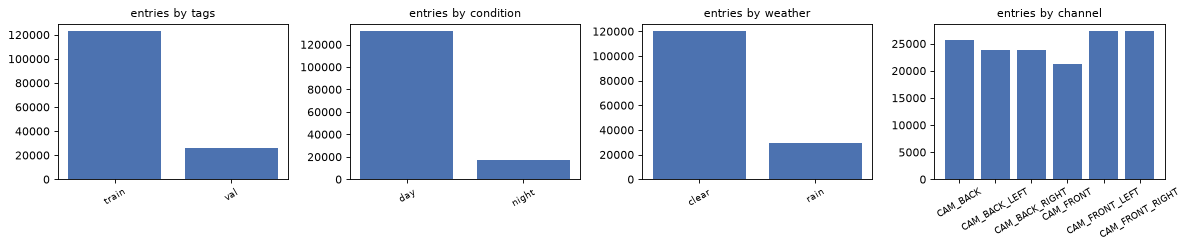

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, field in zip(axes, ("tags", "condition", "weather", "channel")):
    counts = Counter(value for row in rows for value in (row[field] if field == "tags" else [row[field]]))
    ax.bar(list(counts), list(counts.values()), color="#4c72b0")
    ax.set_title(f"entries by {field}")
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
fig.tight_layout()

Every keyword of `cache.rows()` is a filter: `tag`, `scene`, `channel`, `condition` (`day` or `night`) and `weather` (`clear` or `rain`). Filters combine with *and*. `cache.entries(...)` takes the same filters and opens each entry's meta (section 3).

The condition and the weather come from the scene description in the nuScenes tables, so every image of a scene shares them.

In [7]:
combos = Counter((row["condition"], row["weather"]) for row in rows)
display(table(["condition", "weather", "entries"], [(c, w, n) for (c, w), n in sorted(combos.items())]))

front_val = cache.rows(tag="val", channel="CAM_FRONT")
print(f"{len(front_val)} val entries of CAM_FRONT, from {len({r['scene'] for r in front_val})} scenes")

| condition | weather | entries |
|---|---|---|
| day | clear | 105596 |
| day | rain | 26368 |
| night | clear | 14639 |
| night | rain | 2807 |

3760 val entries of CAM_FRONT, from 150 scenes


Within a scene, `index` is the position of the keyframe. nuScenes keyframes come at 2 Hz, so a scene of 40 keyframes is 20 seconds of driving. The entry key is `<scene>_<index>_<camera>`, and it is also the file name of the entry.

In [8]:
scene = front_val[0]["scene"]
keyframes = cache.rows(scene=scene, channel="CAM_FRONT")
print(f"{scene}: {len(keyframes)} keyframes of CAM_FRONT, about {len(keyframes) / 2:.0f} s")
print("first keys:", [r["key"] for r in keyframes[:3]])

scene-0003: 25 keyframes of CAM_FRONT, about 12 s
first keys: ['scene-0003_000_CAM_FRONT', 'scene-0003_001_CAM_FRONT', 'scene-0003_003_CAM_FRONT']


## 3. One entry

`cache.entry(key)` opens one entry: it reads the `meta` (the `.json` file) and keeps the path of the arrays (the `.npz` file). The arrays stay on disk until `entry.load()` reads them.

**Settings to change:** `KEY` is any key from `cache.rows()`. The key below is a day scene with pedestrians, chosen so that the plots of the labels and the temporal spread show visible structure.

In [9]:
KEY = "scene-0553_020_CAM_FRONT"

try:
    entry = cache.entry(KEY)
except KeyError:
    KEY = rows[len(rows) // 2]["key"]
    entry = cache.entry(KEY)
meta = entry.meta
print(f"{KEY}: {entry.path.stat().st_size / 1e6:.1f} MB at {entry.path}")

scene-0553_020_CAM_FRONT: 1.4 MB at /scratch1/naday/confhead-cache/nuscenes-trainval/entries/scene-0553/scene-0553_020_CAM_FRONT.npz


The meta records where the image came from, the grid, and the results of the two fits. The **fits** are the most important fields. The model's disparity is inverse depth only *up to a scale and a shift*, and each fit gives the scale and the shift that make it metric: one fit uses the lidar, and the other the radar. Section 4.2 shows them.

In [10]:
display(table(["field", "value"], [
    ("scene, index, channel", f"{meta['scene']}, {meta['index']}, {meta['channel']}"),
    ("condition, weather", f"{meta['condition']}, {meta['weather']}"),
    ("image", f"{meta['image']['width']} x {meta['image']['height']} px, {meta['image']['path']}"),
    ("model input", f"{meta['model_size'][0]} x {meta['model_size'][1]} px (short side resized, then rounded to 14 px patches)"),
    ("grid", f"{meta['grid_size'][0]} x {meta['grid_size'][1]} cells, features from {meta['tap']}"),
    ("fit_lidar", meta["fit_lidar"]),
    ("fit_radar", meta["fit_radar"]),
    ("temporal", f"{meta['temporal']['status']}, {len(meta['temporal'].get('neighbors', []))} neighbor frames"),
    ("lidar", f"{meta['lidar']['points']} points from {meta['lidar']['sweeps']} sweep"),
    ("radar", f"{meta['radar']['points']} points from {meta['radar']['sweeps']} sweeps (5 radars x 5 sweeps)"),
]))

| field | value |
|---|---|
| scene, index, channel | scene-0553, 20, CAM_FRONT |
| condition, weather | day, clear |
| image | 1600 x 900 px, samples/CAM_FRONT/n008-2018-08-28-16-43-51-0400__CAM_FRONT__1535489305912404.jpg |
| model input | 924 x 518 px (short side resized, then rounded to 14 px patches) |
| grid | 132 x 74 cells, features from output_conv1 |
| fit_lidar | {'scale': 0.014439629972020666, 'shift': 0.0012243745378574672, 'n': 2298, 'rmse': 0.015701377512305503} |
| fit_radar | {'scale': 0.003160112524869016, 'shift': 0.017506974581106876, 'n': 154, 'rmse': 0.021464800670701844} |
| temporal | ok, 4 neighbor frames |
| lidar | 2298 points from 1 sweep |
| radar | 154 points from 25 sweeps (5 radars x 5 sweeps) |

`entry.load()` returns the arrays as a dict. `entry.load(["lidar", "radar"])` loads only the named arrays, as the training set does.

| Array | Shape | Description |
|---|---|---|
| `features` | (64, h, w) float16 | the decoder features at the tap; the head's main input |
| `disparity_grid` | (h, w) float32 | the model's disparity, averaged onto the grid |
| `temporal_relstd` | (h, w) float16 | std / mean of the inverse depth of a cell across the neighbor frames |
| `temporal_count` | (h, w) uint8 | how many frames see the cell, the keyframe included |
| `lidar` | (N, 6) float32 | one row per point: u, v, z, dt, sweep, disparity |
| `radar` | (M, 6) float32 | the same for the radar points |

h and w are the grid size, and H and W the image size. Every map covers the whole image, so cell (row, col) covers the pixels at (row * H / h, col * W / w). The point rows are in the pixels of the original image: `u`, `v` the position, `z` the depth in meters along the camera axis, `dt` the time of the sweep relative to the image in seconds, `sweep` 0 for the keyframe sweep, and `disparity` the model's value at that pixel.

In [11]:
a = entry.load()
display(table(["array", "shape", "dtype", "MB"], [(k, v.shape, v.dtype, f"{v.nbytes / 1e6:.2f}") for k, v in a.items()]))
print("the same shapes, from the meta alone:", {k: v["shape"] for k, v in meta["arrays"].items()})

| array | shape | dtype | MB |
|---|---|---|---|
| features | (64, 74, 132) | float16 | 1.25 |
| disparity_grid | (74, 132) | float32 | 0.04 |
| temporal_relstd | (74, 132) | float16 | 0.02 |
| temporal_count | (74, 132) | uint8 | 0.01 |
| lidar | (2298, 6) | float32 | 0.06 |
| radar | (154, 6) | float32 | 0.00 |

the same shapes, from the meta alone: {'features': [64, 74, 132], 'disparity_grid': [74, 132], 'temporal_relstd': [74, 132], 'temporal_count': [74, 132], 'lidar': [2298, 6], 'radar': [154, 6]}


`entry.image()` reads the camera image from the dataset. The cache holds no pixels, only the path of the image relative to the dataroot.

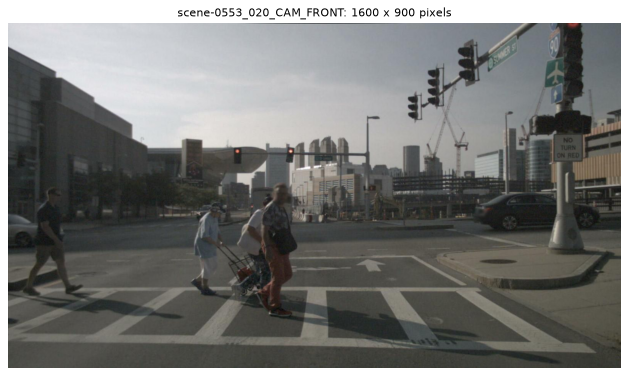

In [12]:
rgb = entry.image()
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.imshow(rgb)
ax.set_axis_off()
ax.set_title(f"{KEY}: {rgb.shape[1]} x {rgb.shape[0]} pixels")
plt.show()

## 4. Visualize each array

`confhead.plot` has the drawing functions. `draw_points` puts points on an image. `draw_map` puts a grid map over the field of view of the image, one block per cell, with an optional gray image under it and a mask of the cells to show. Both work on any matplotlib axes.

### 4.1 The points

The lidar dots are colored by depth. Each radar circle is labeled with its depth in meters. Only the keyframe sweep of the radar is drawn here (`sweep == 0`); the cache holds 5 sweeps per radar, which section 7 uses.

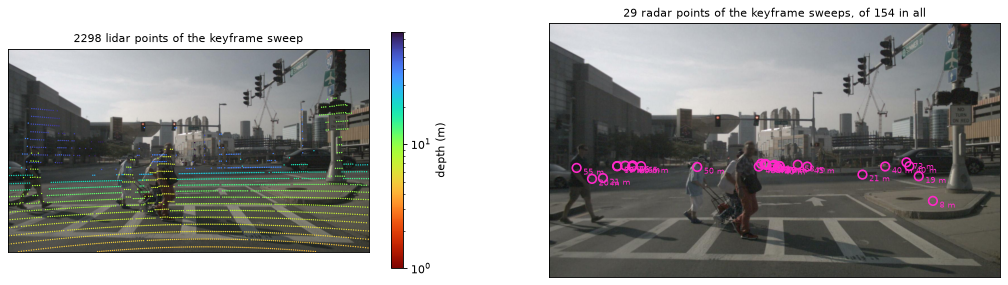

In [13]:
lidar, radar = a["lidar"], a["radar"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.8))
dots = draw_points(ax1, rgb, lidar=lidar)
ax1.set_title(f"{len(lidar)} lidar points of the keyframe sweep")
fig.colorbar(dots, ax=ax1, shrink=0.8, label="depth (m)")
keyframe_radar = radar[radar[:, 4] == 0]
draw_points(ax2, rgb, radar=keyframe_radar)
ax2.set_title(f"{len(keyframe_radar)} radar points of the keyframe sweeps, of {len(radar)} in all")
plt.show()

Each point row holds the position of the point, its depth, and the model's disparity at its pixel. The `dt` column is 0 for the lidar keyframe sweep and negative for the earlier radar sweeps.

In [14]:
display(table(["column"] + ["u", "v", "z", "dt", "sweep", "disparity"],
              [["lidar[0]"] + [f"{x:.3f}" for x in lidar[0]], ["radar[-1]"] + [f"{x:.3f}" for x in radar[-1]]]))
print(f"lidar depth from {lidar[:, 2].min():.1f} to {lidar[:, 2].max():.1f} m; radar sweeps {sorted(set(radar[:, 4].astype(int).tolist()))}")

| column | u | v | z | dt | sweep | disparity |
|---|---|---|---|---|---|---|
| lidar[0] | 3.173 | 598.461 | 19.986 | 0.035 | 0.000 | 4.269 |
| radar[-1] | 764.636 | 498.394 | 72.940 | -0.224 | 4.000 | 1.347 |

lidar depth from 4.3 to 79.8 m; radar sweeps [0, 1, 2, 3, 4]


### 4.2 From disparity to depth

The model predicts disparity: a number that grows as things get closer, but with its own scale and shift for every image. To compare it with meters, the build fits `1 / z = scale * disparity + shift` by least squares over the points, once with the lidar and once with the radar. `entry.fit("lidar")` returns that fit, and `fit.depth(disparity, min_depth, max_depth)` applies it.

The left plot shows the lidar fit: each dot is one lidar point, and the line is the fit. Dots close to the line mean that the model's depth agrees with the lidar, up to the scale. The right plot shows how much worse the radar fit is: it has fewer points, mostly on cars, and a larger spread.

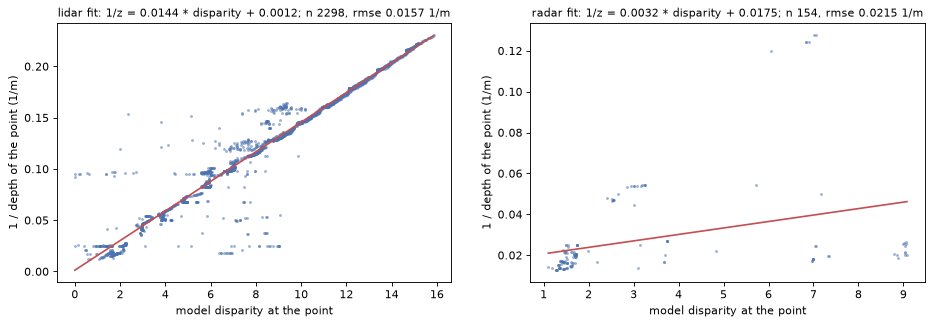

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (name, pts) in zip(axes, (("lidar", lidar), ("radar", radar))):
    fit = entry.fit(name)
    ax.scatter(pts[:, 5], 1 / pts[:, 2], s=3, alpha=0.4, color="#4c72b0")
    ax.set(xlabel="model disparity at the point", ylabel="1 / depth of the point (1/m)")
    if fit is None:
        ax.set_title(f"{name}: no fit (too few points, or a scale that is not positive)")
        continue
    x = np.array([pts[:, 5].min(), pts[:, 5].max()])
    ax.plot(x, fit.scale * x + fit.shift, color="#c44e52")
    ax.set_title(f"{name} fit: 1/z = {fit.scale:.4f} * disparity + {fit.shift:.4f}; n {fit.n}, rmse {fit.rmse:.4f} 1/m")

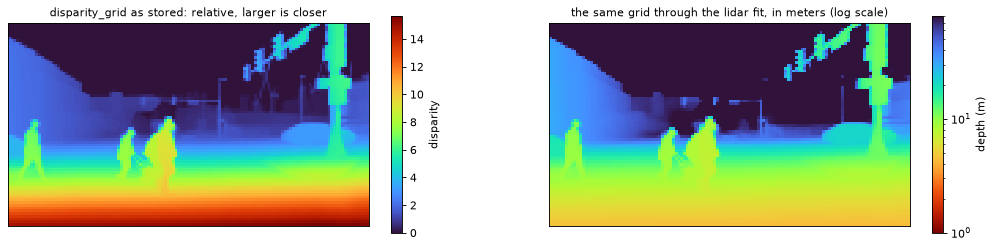

In [16]:
from matplotlib.colors import LogNorm

fit = entry.fit("lidar")
size = (meta["image"]["width"], meta["image"]["height"])
depth = fit.depth(a["disparity_grid"].astype(np.float64), min_depth=1.0, max_depth=80.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.4))
im = draw_map(ax1, a["disparity_grid"], size, cmap="turbo")
ax1.set_title("disparity_grid as stored: relative, larger is closer")
fig.colorbar(im, ax=ax1, shrink=0.8, label="disparity")
im = draw_map(ax2, depth, size, cmap="turbo_r", norm=LogNorm(1, 80))
ax2.set_title("the same grid through the lidar fit, in meters (log scale)")
fig.colorbar(im, ax=ax2, shrink=0.8, label="depth (m)")
plt.show()

### 4.3 The temporal spread

Each keyframe image has neighbor images: the camera frames before and after it, about 0.1 s apart, two on each side. The build lifts each grid cell to 3D with the keyframe depth, moves it into each neighbor camera with the ego poses, reads the neighbor's depth there, and moves the result back into the keyframe camera. For a static scene and a correct pose, every frame gives the same point, so the spread is 0 however the car moves. Moving objects, occlusions, and unstable depth raise it. The header of [`cache/temporal.py`](../src/confhead/cache/temporal.py) gives the steps.

`temporal_relstd` is std / mean of the inverse depths, so 0.05 means about 5 % variation. `temporal_count` says how many frames see the cell. A cell seen by one frame only (the keyframe) has no spread, so the map leaves it out.

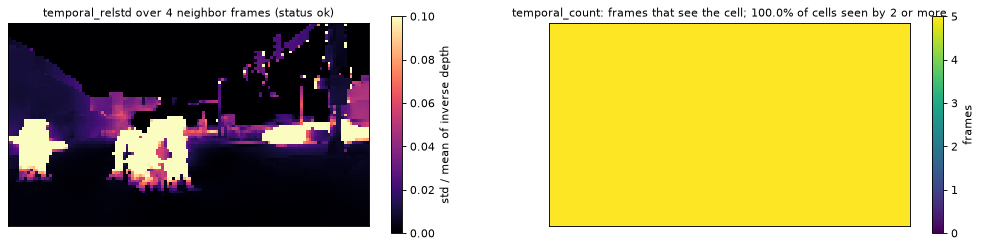

In [17]:
count = a["temporal_count"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.4))
im = draw_map(ax1, a["temporal_relstd"], size, image=rgb, mask=count >= 2, cmap="magma", vmin=0, vmax=0.1)
ax1.set_title(f"temporal_relstd over {len(meta['temporal']['neighbors'])} neighbor frames (status {meta['temporal']['status']})")
fig.colorbar(im, ax=ax1, shrink=0.8, label="std / mean of inverse depth")
im = draw_map(ax2, count, size, cmap="viridis", vmin=0, vmax=count.max())
ax2.set_title(f"temporal_count: frames that see the cell; {np.mean(count >= 2):.1%} of cells seen by 2 or more")
fig.colorbar(im, ax=ax2, shrink=0.8, label="frames")
plt.show()

### 4.4 The features

The 64 feature channels are the decoder activations just before the model's last layer. `features_rgb` maps them to three colors with a principal component analysis, so that similar colors mean similar features. The plots of single channels show that each channel responds to different content in the image.

features: mean 1.608, std 14.922, range -70.94 to 138.75


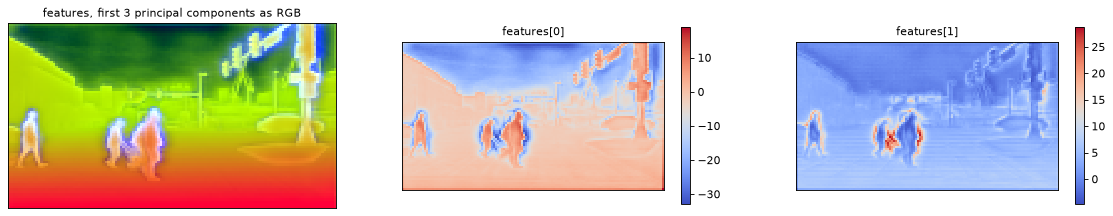

In [18]:
features = a["features"].astype(np.float32)
fig, axes = plt.subplots(1, 3, figsize=(18, 3.6))
axes[0].imshow(features_rgb(features), extent=(-0.5, size[0] - 0.5, size[1] - 0.5, -0.5), interpolation="nearest")
axes[0].set_title("features, first 3 principal components as RGB")
for ax, channel in zip(axes[1:], (0, 1)):
    im = draw_map(ax, features[channel], size, cmap="coolwarm")
    ax.set_title(f"features[{channel}]")
    fig.colorbar(im, ax=ax, shrink=0.8)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
print(f"features: mean {features.mean():.3f}, std {features.std():.3f}, range {features.min():.2f} to {features.max():.2f}")

### 4.5 Everything on one page

`entry_figure(entry)` draws one entry as the 3 x 2 figure of the README: the image with its lidar, the depth, the temporal spread, the features, the lidar labels (section 6), and the radar residual (section 7). It is the quickest way to look at a new entry. `examples/preview_cache.py` writes these figures for a list of keys.

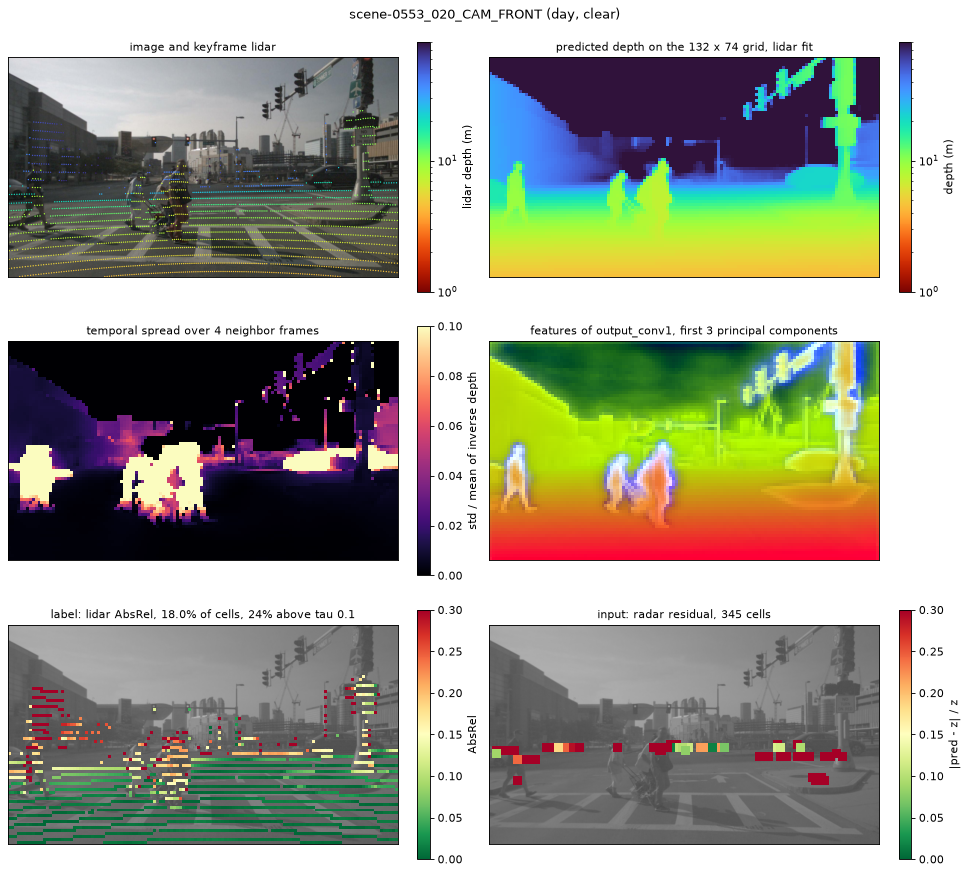

In [19]:
entry_figure(entry)

## 5. The grid and the image

The grid is the model's 14 px patch grid times `grid.patch_multiple`. The dense maps all share it. A cell is a block of pixels, and a point lands in the cell that covers its pixel. [`geometry.py`](../src/confhead/geometry.py) has the conversions: `rescale_coords` moves pixel coordinates between an image and a map of another size, and `rasterize` puts points onto a grid, keeping the nearest point (the smallest depth) when several land in one cell.

The crop below shows the depth cells over the pixels they cover, with the lidar points on top.

grid 132 x 74 over an image of 1600 x 900: each cell covers 12.1 x 12.2 pixels
the first lidar point, at pixel (3.2, 598.5), lands in cell (col 0, row 49)


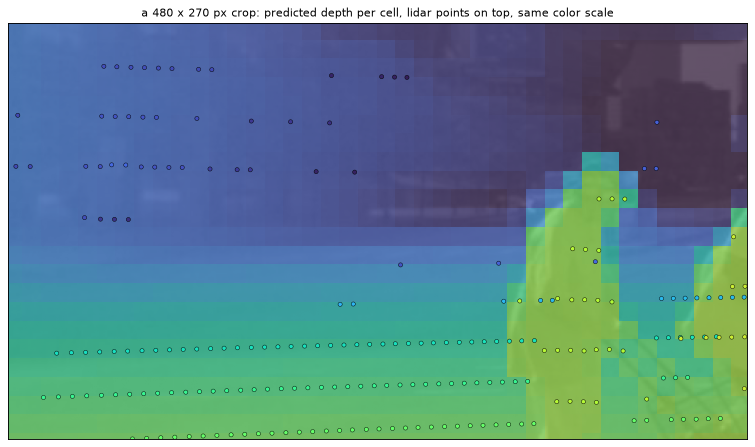

In [20]:
from confhead.geometry import rescale_coords

gw, gh = meta["grid_size"]
W, H = size
print(f"grid {gw} x {gh} over an image of {W} x {H}: each cell covers {W / gw:.1f} x {H / gh:.1f} pixels")
u, v = lidar[0, :2]
x, y = rescale_coords(u, v, (W, H), (gw, gh))
print(f"the first lidar point, at pixel ({u:.1f}, {v:.1f}), lands in cell (col {round(x)}, row {round(y)})")

x0, y0, cw, ch = int(W * 0.10), int(H * 0.42), 480, 270  # Settings to change: the crop, in pixels
fig, ax = plt.subplots(figsize=(12, 6.75))
draw_map(ax, depth, size, image=rgb, cmap="turbo_r", norm=LogNorm(1, 80), alpha=0.55)
inside = (lidar[:, 0] > x0) & (lidar[:, 0] < x0 + cw) & (lidar[:, 1] > y0) & (lidar[:, 1] < y0 + ch)
ax.scatter(lidar[inside, 0], lidar[inside, 1], c=lidar[inside, 2], cmap="turbo_r", norm=LogNorm(1, 80), s=14,
           edgecolors="black", linewidths=0.4)
ax.set_xlim(x0, x0 + cw)
ax.set_ylim(y0 + ch, y0)
ax.set_title(f"a {cw} x {ch} px crop: predicted depth per cell, lidar points on top, same color scale")
plt.show()

## 6. The labels

The head learns where the model's depth is wrong. For each lidar point, the label code compares the model's depth at that pixel (disparity through the lidar fit) with the lidar depth:

    AbsRel = |predicted - z| / z

Each grid cell takes the AbsRel of the nearest lidar point (the smallest depth) that lands in it. The **target** is 1 where AbsRel is above `tau` and 0 elsewhere. The **mask** is 1 where a cell has a lidar point; cells without one have no label and must not count in the loss.

`lidar_labels(meta, arrays, LabelConfig(...))` computes all three at load time.

**Settings to change:** `tau` is the AbsRel above which a cell counts as wrong. `align="radar"` uses the radar fit instead, the fit that a deployed car could make.

abs_rel (74, 132) float32, target (74, 132) float32, mask (74, 132) bool
18.0% of cells hold a label; 24.2% of those are 1 (AbsRel > 0.1)


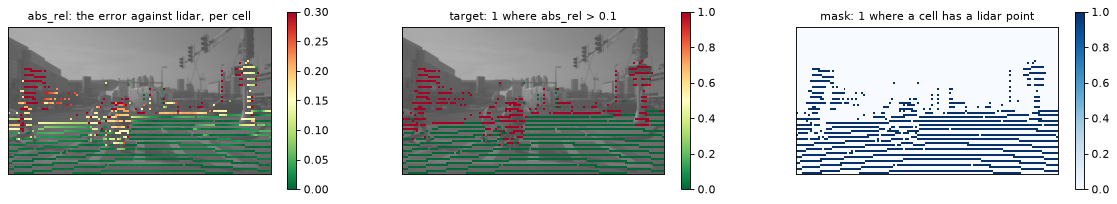

In [21]:
from confhead.labels import lidar_labels

labels = LabelConfig(tau=0.10, align="lidar")
abs_rel, target, mask = lidar_labels(meta, a, labels)

print(f"abs_rel {abs_rel.shape} {abs_rel.dtype}, target {target.shape} {target.dtype}, mask {mask.shape} {mask.dtype}")
print(f"{mask.mean():.1%} of cells hold a label; {target[mask].mean():.1%} of those are 1 (AbsRel > {labels.tau})")

fig, axes = plt.subplots(1, 3, figsize=(18, 3.6))
im = draw_map(axes[0], abs_rel, size, image=rgb, mask=mask, cmap="RdYlGn_r", vmin=0, vmax=3 * labels.tau)
axes[0].set_title("abs_rel: the error against lidar, per cell")
fig.colorbar(im, ax=axes[0], shrink=0.8)
im = draw_map(axes[1], target, size, image=rgb, mask=mask, cmap="RdYlGn_r", vmin=0, vmax=1)
axes[1].set_title(f"target: 1 where abs_rel > {labels.tau}")
fig.colorbar(im, ax=axes[1], shrink=0.8)
im = draw_map(axes[2], mask, size, image=rgb, cmap="Blues", vmin=0, vmax=1)
axes[2].set_title("mask: 1 where a cell has a lidar point")
fig.colorbar(im, ax=axes[2], shrink=0.8)
plt.show()

The distribution of the error decides how hard the task is. Most cells are close to the lidar, and a tail is far off; the cells above `tau` are the positive labels. The table shows how the share of positive labels changes with `tau`.

| tau | positive labels |
|---|---|
| 0.05 | 29.5% |
| 0.1 | 24.2% |
| 0.15 | 18.4% |
| 0.2 | 13.0% |
| 0.3 | 8.4% |

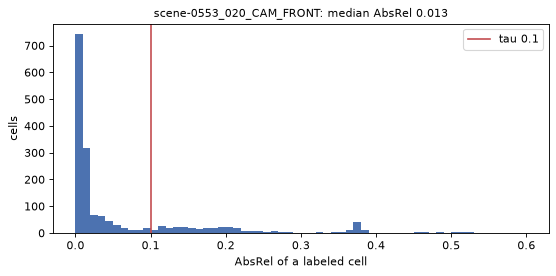

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(abs_rel[mask], bins=np.linspace(0, 0.6, 61), color="#4c72b0")
ax.axvline(labels.tau, color="#c44e52", label=f"tau {labels.tau}")
ax.set(xlabel="AbsRel of a labeled cell", ylabel="cells", title=f"{KEY}: median AbsRel {np.median(abs_rel[mask]):.3f}")
ax.legend()

display(table(["tau", "positive labels"],
              [(tau, f"{lidar_labels(meta, a, LabelConfig(tau=tau))[1][mask].mean():.1%}") for tau in (0.05, 0.10, 0.15, 0.20, 0.30)]))

A few entries have no lidar fit: night images where the disparity does not follow the lidar at all, so a fit with a positive scale does not exist. Their `fit_lidar` is `None`, their mask is all zero, and they add nothing to the loss. The radar fit fails more often, because radar has few points.

In [23]:
night = [cache.entry(row) for row in cache.rows(condition="night")[:300]]
print(f"of the first {len(night)} night entries, {sum(e.fit('lidar') is None for e in night)} have no lidar fit "
      f"and {sum(e.fit('radar') is None for e in night)} have no radar fit")

of the first 300 night entries, 13 have no lidar fit and 104 have no radar fit


## 7. The radar channels

Radar is an input of the head, because a deployed car has radar. The head gets two radar channels. The **residual** is `|predicted - z| / z` at each radar point, with the depth from the *radar* fit, because that is the fit a car could make without lidar. The **valid** channel marks the cells that have a radar point. Radar points are sparse, so each point also fills the cells within `radius` cells of its own.

**Settings to change:** `radius` (cells around each point), `max_sweeps` (0 for every cached sweep, 1 for the keyframe sweep only), and `align`, all fields of `RadarConfig`.

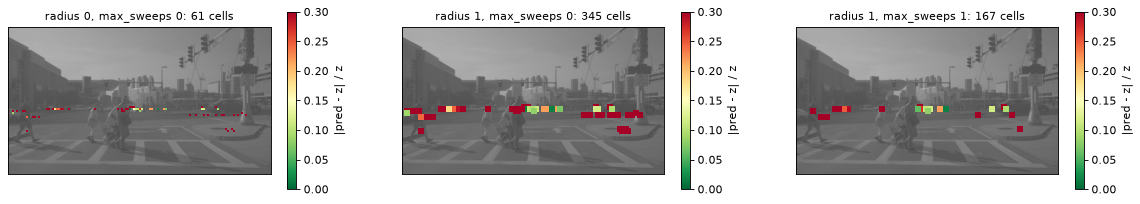

In [24]:
from confhead.dataset import radar_channels

fig, axes = plt.subplots(1, 3, figsize=(18, 3.6))
for ax, cfg in zip(axes, (RadarConfig(radius=0), RadarConfig(radius=1), RadarConfig(radius=1, max_sweeps=1))):
    residual, valid = radar_channels(meta, a, cfg)
    im = draw_map(ax, residual, size, image=rgb, mask=valid > 0, cmap="RdYlGn_r", vmin=0, vmax=0.3)
    ax.set_title(f"radius {cfg.radius}, max_sweeps {cfg.max_sweeps}: {int((valid > 0).sum())} cells")
    fig.colorbar(im, ax=ax, shrink=0.8, label="|pred - z| / z")

## 8. The training set

`ConfidenceDataset` is a PyTorch `Dataset` over a cache. It takes the filters of `cache.rows()`, so `tag="train"` and `tag="val"` give the two splits. Each item is a dict:

| Key | Shape | Description |
|---|---|---|
| `x` | (C + 4, h, w) float32 | the input: the features, the depth, the temporal spread, the radar residual and the radar validity |
| `target` | (1, h, w) float32 | the label, 1 where the depth is wrong |
| `mask` | (1, h, w) float32 | 1 where a label exists |
| `abs_rel` | (1, h, w) float32 | the error itself, for evaluation |
| `key` | str | the entry key |

The depth channel of `x` is the disparity divided by its mean over the image, so that every image has the same scale. `dataset.channel_names` names the channels of `x` in order.

In [25]:
train = ConfidenceDataset(cache, tag="train")
val = ConfidenceDataset(cache, tag="val")
print(f"train {len(train)} entries, val {len(val)} entries")

sample = train[0]
display(table(["key", "type", "shape", "dtype"],
              [(k, type(v).__name__, tuple(v.shape) if hasattr(v, "shape") else "", getattr(v, "dtype", "")) for k, v in sample.items()]))
print(f"channels of x: {train.channel_names[:2]} ... {train.channel_names[62:]}")

train 123079 entries, val 26331 entries


| key | type | shape | dtype |
|---|---|---|---|
| key | str |  |  |
| x | Tensor | (68, 74, 132) | torch.float32 |
| target | Tensor | (1, 74, 132) | torch.float32 |
| mask | Tensor | (1, 74, 132) | torch.float32 |
| abs_rel | Tensor | (1, 74, 132) | torch.float32 |

channels of x: ['feature_0', 'feature_1'] ... ['feature_62', 'feature_63', 'depth', 'temporal_relstd', 'radar_residual', 'radar_valid']


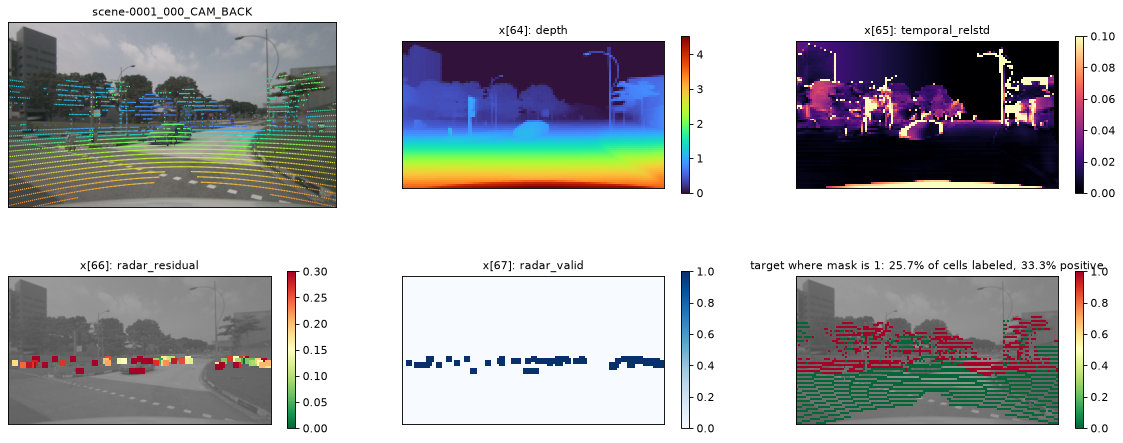

In [26]:
names = train.channel_names
x = sample["x"].numpy()
entry0 = cache.entry(sample["key"])
rgb0 = entry0.image()
size0 = (entry0.meta["image"]["width"], entry0.meta["image"]["height"])

radar_valid = x[names.index("radar_valid")] > 0
panels = [("depth", dict(cmap="turbo"), None), ("temporal_relstd", dict(cmap="magma", vmin=0, vmax=0.1), None),
          ("radar_residual", dict(cmap="RdYlGn_r", vmin=0, vmax=0.3), radar_valid), ("radar_valid", dict(cmap="Blues", vmin=0, vmax=1), None)]

fig, axes = plt.subplots(2, 3, figsize=(18, 7))
axes = list(axes.flat)
draw_points(axes[0], rgb0, lidar=entry0.load(["lidar"])["lidar"])
axes[0].set_title(sample["key"])
for ax, (name, kw, mask_) in zip(axes[1:5], panels):
    im = draw_map(ax, x[names.index(name)], size0, image=rgb0 if mask_ is not None else None, mask=mask_, **kw)
    ax.set_title(f"x[{names.index(name)}]: {name}")
    fig.colorbar(im, ax=ax, shrink=0.8)
im = draw_map(axes[5], sample["target"][0].numpy(), size0, image=rgb0, mask=sample["mask"][0].numpy() > 0, cmap="RdYlGn_r", vmin=0, vmax=1)
axes[5].set_title(f"target where mask is 1: {sample['mask'].mean():.1%} of cells labeled, {sample['target'].sum() / sample['mask'].sum():.1%} positive")
fig.colorbar(im, ax=axes[5], shrink=0.8)
plt.show()

`HeadInputs` selects the channel groups of `x` for the ablations: a head without radar, or without the features, gets the same labels with fewer channels. It also holds the `LabelConfig` and the `RadarConfig` of sections 6 and 7.

In [27]:
variants = {
    "all inputs": HeadInputs(),
    "no radar": HeadInputs(radar=False),
    "no temporal": HeadInputs(temporal=False),
    "depth and radar only": HeadInputs(features=False, temporal=False),
    "tau 0.2, radar radius 2": HeadInputs(labels=LabelConfig(tau=0.2), radar_cfg=RadarConfig(radius=2)),
}
display(table(["variant", "channels of x", "last channels"],
              [(name, len(ConfidenceDataset(cache, inputs, tag="train").channel_names),
                ", ".join(ConfidenceDataset(cache, inputs, tag="train").channel_names[-3:])) for name, inputs in variants.items()]))

| variant | channels of x | last channels |
|---|---|---|
| all inputs | 68 | temporal_relstd, radar_residual, radar_valid |
| no radar | 66 | feature_63, depth, temporal_relstd |
| no temporal | 67 | depth, radar_residual, radar_valid |
| depth and radar only | 3 | depth, radar_residual, radar_valid |
| tau 0.2, radar radius 2 | 68 | temporal_relstd, radar_residual, radar_valid |

A standard `DataLoader` batches the items. Loading an item reads one `.npz` from disk and computes its labels, so `num_workers` above 0 helps on a shared file system. The time per item below is a guide for how many workers a training job needs.

In [28]:
from torch.utils.data import DataLoader

loader = DataLoader(train, batch_size=8, shuffle=True, num_workers=0)
t0 = time.perf_counter()
batch = next(iter(loader))
seconds = time.perf_counter() - t0
print(f"one batch of {len(batch['key'])} in {seconds:.2f} s, {seconds / len(batch['key']) * 1000:.0f} ms per item with num_workers=0")
for k in ("x", "target", "mask", "abs_rel"):
    print(f"{k:8} {tuple(batch[k].shape)} {batch[k].dtype}")
print(f"labeled cells in the batch: {batch['mask'].mean():.1%}; positive among them: {batch['target'].sum() / batch['mask'].sum():.1%}")

one batch of 8 in 0.77 s, 97 ms per item with num_workers=0
x        (8, 68, 74, 132) torch.float32
target   (8, 1, 74, 132) torch.float32
mask     (8, 1, 74, 132) torch.float32
abs_rel  (8, 1, 74, 132) torch.float32
labeled cells in the batch: 21.0%; positive among them: 27.8%


## 9. Statistics over the cache

This section reads a sample of entries spread over the whole cache and measures the label coverage, the share of positive labels, and the radar coverage, grouped by camera and by condition. It loads only the point arrays of each entry, so it is quick.

**Settings to change:** `N` is the number of entries in the random sample. 240 takes a few seconds; the whole trainval cache takes about an hour.

240 entries in 25.7 s; 1 without a lidar fit


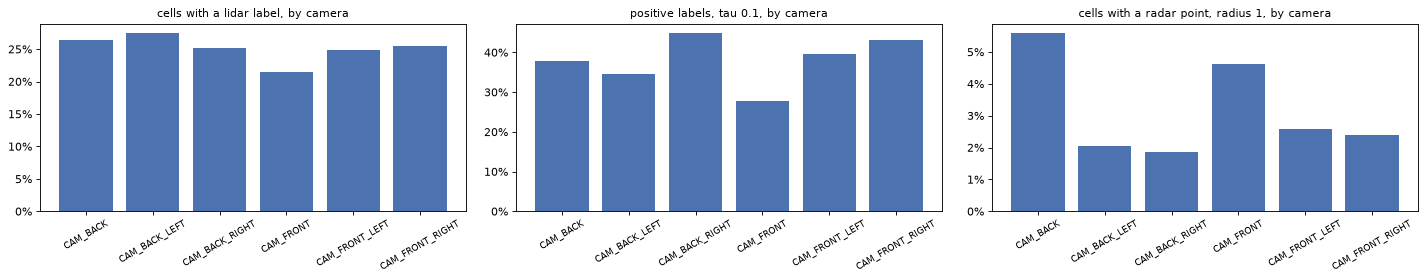

In [29]:
N = 240
rng = np.random.default_rng(0)
sample_rows = [rows[i] for i in sorted(rng.choice(len(rows), size=min(N, len(rows)), replace=False))]
stats = []
t0 = time.perf_counter()
for row in sample_rows:
    e = cache.entry(row)
    arrays = e.load(["lidar", "radar"])
    abs_rel_, target_, mask_ = lidar_labels(e.meta, arrays, LabelConfig())
    _, valid_ = radar_channels(e.meta, arrays, RadarConfig())
    stats.append({**row, "coverage": mask_.mean(), "positive": target_[mask_].mean() if mask_.any() else np.nan,
                  "median_abs_rel": np.median(abs_rel_[mask_]) if mask_.any() else np.nan, "radar_cells": (valid_ > 0).mean(),
                  "no_fit": e.fit("lidar") is None})
print(f"{len(stats)} entries in {time.perf_counter() - t0:.1f} s; {sum(s['no_fit'] for s in stats)} without a lidar fit")


def by(field, value):
    groups = sorted({s[field] for s in stats})
    return groups, [np.nanmean([s[value] for s in stats if s[field] == g]) for g in groups]


fig, axes = plt.subplots(1, 3, figsize=(18, 3.6))
for ax, (field, value, title) in zip(axes, (("channel", "coverage", "cells with a lidar label"),
                                            ("channel", "positive", "positive labels, tau 0.1"),
                                            ("channel", "radar_cells", "cells with a radar point, radius 1"))):
    groups, means = by(field, value)
    ax.bar(groups, means, color="#4c72b0")
    ax.set_title(f"{title}, by camera")
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout()

|  | entries | label coverage | positive labels | median AbsRel |
|---|---|---|---|---|
| day | 203 | 25.0% | 35.2% | 0.075 |
| night | 37 | 26.3% | 54.6% | 0.130 |

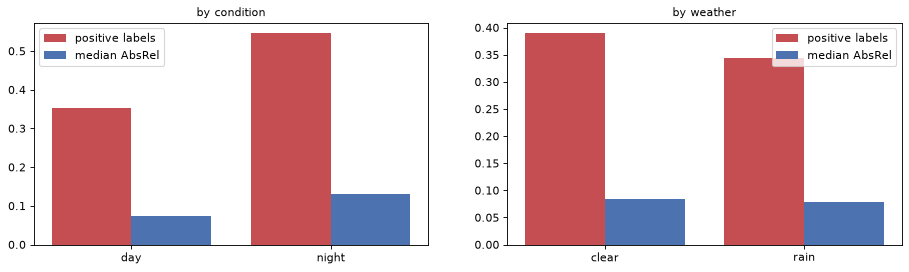

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, field in zip(axes, ("condition", "weather")):
    groups, positive = by(field, "positive")
    _, median = by(field, "median_abs_rel")
    ax.bar(np.arange(len(groups)) - 0.2, positive, 0.4, label="positive labels", color="#c44e52")
    ax.bar(np.arange(len(groups)) + 0.2, median, 0.4, label="median AbsRel", color="#4c72b0")
    ax.set_xticks(range(len(groups)), groups)
    ax.set_title(f"by {field}")
    ax.legend()
display(table(["", "entries", "label coverage", "positive labels", "median AbsRel"],
              [(g, sum(s["condition"] == g for s in stats), f"{np.nanmean([s['coverage'] for s in stats if s['condition'] == g]):.1%}",
                f"{np.nanmean([s['positive'] for s in stats if s['condition'] == g]):.1%}",
                f"{np.nanmean([s['median_abs_rel'] for s in stats if s['condition'] == g]):.3f}") for g in sorted({s["condition"] for s in stats})]))

Compare the cameras, and day against night. On the mini cache, night is harder: the median error and the share of wrong cells both go up. A confidence head has to learn to predict differences of this kind.

## 10. Toward training

A head is a small network over `x` that outputs one logit per cell. The loss is a binary cross-entropy that counts only the labeled cells: multiply by the mask and divide by its sum. The cell below shows the input, the output, and the loss on one batch, with a placeholder head.

In [31]:
import torch
import torch.nn.functional as F
from torch import nn

head = nn.Sequential(nn.Conv2d(len(train.channel_names), 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 1, 1))
logits = head(batch["x"])
loss = (F.binary_cross_entropy_with_logits(logits, batch["target"], reduction="none") * batch["mask"]).sum() / batch["mask"].sum()
print(f"logits {tuple(logits.shape)}, masked loss {loss.item():.3f}; a head that outputs 0 everywhere gets log 2 = {np.log(2):.3f}")

with torch.no_grad():
    predicted = (logits > 0).float()
    labeled = batch["mask"] > 0
    accuracy = (predicted[labeled] == batch["target"][labeled]).float().mean()
    always_zero = 1 - batch["target"][labeled].mean()
print(f"accuracy on labeled cells {accuracy:.1%}, against {always_zero:.1%} for a head that always says the depth is right")

logits (8, 1, 74, 132), masked loss 0.550; a head that outputs 0 everywhere gets log 2 = 0.693
accuracy on labeled cells 72.3%, against 72.2% for a head that always says the depth is right


Points to keep in mind when you write the real head:

- Every loss and every metric runs over the labeled cells only (the mask). Accuracy is a weak metric here because most labels are 0; use AUROC or precision and recall at a threshold, computed over the labeled cells of the whole split.
- The features are raw: their std is about 15 and their range is about -70 to 140 (section 4.4), while the other channels are near 0 to 1. Standardize the features per channel before the first layer, or the first steps of training are spent on the scale alone.
- `tau`, the radar radius, and the channel groups are all set through `HeadInputs`, so changing them needs no rebuild.
- Night entries without a lidar fit have an all-zero mask. They cost a read and add nothing to the loss; filter them out with `entry.fit("lidar") is None` if that matters.
- Following [`design.md`](../design.md), the model, the loss, and the metrics go in `src/confhead/` as functions, and a script in `examples/` runs the training. This notebook, a test, and a CARC job then use the same code.

## 11. Optional: the raw dataset

The cache was made from nuScenes, and `NuScenes` reads the dataset without the nuScenes devkit. You need it when you want something the cache does not hold, for example the neighbor images, more sweeps, or a camera the cache left out. Each `Item` is one camera image with its calibration, its neighbor images, and the lidar and radar sweeps with their transforms into the camera. `load_points` projects any of these sweeps into the image.

> **Note.** `NuScenes(...)` loads every table of the version. For `v1.0-trainval` that is about 20 s and several GB of memory, so run this section on a JupyterLab session with 16 GB or more. On `v1.0-mini` it is instant.

850 scenes on disk; item scene-0553_020_CAM_FRONT has 4 neighbors, 1 lidar sweep and 25 radar sweeps


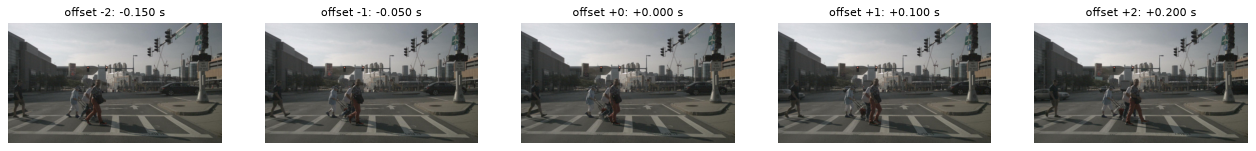

In [32]:
from confhead import NuScenes, load_points

nusc = NuScenes(cache.dataroot, cache.settings["source"]["version"])
item = nusc.item(nusc.scene(meta["scene"]), meta["index"], meta["channel"], offsets=(-2, -1, 1, 2), radar_sweeps=5)
print(f"{len(nusc.scenes)} scenes on disk; item {item.key} has {len(item.neighbors)} neighbors, "
      f"{len(item.lidar)} lidar sweep and {len(item.radar)} radar sweeps")

views = sorted([(0, item.view)] + list(item.neighbors), key=lambda p: p[0])
fig, axes = plt.subplots(1, len(views), figsize=(4 * len(views), 2.6))
for ax, (offset, view) in zip(axes, views):
    ax.imshow(plt.imread(view.image_path))
    ax.set_axis_off()
    ax.set_title(f"offset {offset:+d}: {(view.timestamp - item.view.timestamp) / 1e6:+.3f} s")

`load_points` turns the sweeps into the same point rows as the cache, without the disparity column: (u, v, z, dt, sweep). The build adds the sixth column by sampling the model's disparity at each point.

lidar (2298, 5), radar (154, 5); the cache holds (2298, 6) and (154, 6)


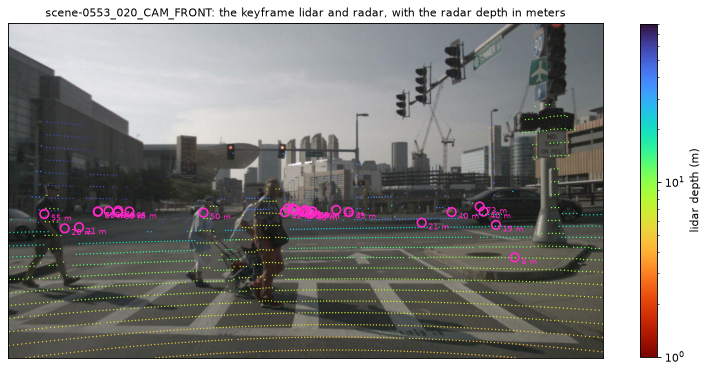

In [33]:
lidar_raw = load_points(item.lidar, item.view)
radar_raw = load_points(item.radar, item.view)
print(f"lidar {lidar_raw.shape}, radar {radar_raw.shape}; the cache holds {a['lidar'].shape} and {a['radar'].shape}")

fig, ax = plt.subplots(figsize=(12, 6.75))
dots = draw_points(ax, plt.imread(item.view.image_path), lidar=lidar_raw, radar=radar_raw[radar_raw[:, 4] == 0])
ax.set_title(f"{item.key}: the keyframe lidar and radar, with the radar depth in meters")
fig.colorbar(dots, ax=ax, shrink=0.8, label="lidar depth (m)")
plt.show()

## Where to go next

- [`train-head.ipynb`](train-head.ipynb) trains the real head on this cache.
- [`README.md`](../README.md) lists every module and the example scripts.
- [`design.md`](../design.md) gives the rules behind the cache: what it stores, why, and the frames and units.
- [`guides/cache-building-on-carc.md`](../guides/cache-building-on-carc.md) explains how to build the trainval cache on CARC.
- [`src/confhead/dataset.py`](../src/confhead/dataset.py) holds the roughly 100 lines that turn an entry into a training item. Read it before you write the head.